# 03. A vida de um contrato FAR: pré-obra, obra e entrada das famílias

A curva S olha só para a obra. O contrato do FAR é mais longo: começa na assinatura, atravessa a cláusula suspensiva e a preparação, vira obra, chega a 100% e ainda espera habite-se, designação das unidades e assinatura dos contratos das famílias. Este notebook organiza cada APF do Novo MCMV-FAR nessa escala temporal, em três fases:

1. **Pré-obra**: da contratação ao início da obra. Inclui a cláusula suspensiva (o contrato fica suspenso até o ente apresentar a lei autorizativa ou outra condição, em até 90 dias pelo MNPO) e a preparação do canteiro.
2. **Obra**: do início físico aos 100% de execução. É onde a curva S vive.
3. **Pós-obra**: dos 100% à entrada das famílias (habite-se, designação das UH, contrato com as famílias, chaves).

Depois, a curva média da carteira sobre essa escala, a pergunta "em que fase o atraso acontece" e o caso do Residencial Vila Florida V (Matão/SP), que terminou a obra e ficou parado no fim.

**De onde vem cada marco (tudo do banco do Lab, 10.0.0.50):**

| Marco | Coluna | Tabela |
|---|---|---|
| Contratação | `dt_contratacao` | `ouro.ouro_far_ficha_empreendimento` |
| Cláusula suspensiva e fim dela | `etapa = 'Cláusula suspensiva'`, `pct_marco_fim_suspensiva` | `ouro.ouro_far_serie_mensal_apf` (regra do modelo dbt da série) |
| Início da obra (cadastro) | `dt_inicio_obra` | `prata.prata_far_cadastro_pj` (MONIT cadastro PJ) |
| Primeira liberação | `vr_liberado_mes > 0` | `ouro.ouro_far_serie_mensal_apf` (livro-razão MONIT) |
| Início físico observado | `etapa = 'Em execução'` | `ouro.ouro_far_serie_mensal_apf` |
| 100% de execução | `pct_obra_realizada >= 99,99` | `ouro.ouro_far_serie_mensal_apf` |
| Obra concluída (MONIT) | `situacao_obra = 'CONCLUÍDA'`, `dt_alteracao_situacao` | série e `prata.prata_far_obra_mensal` |
| Promessa de conclusão | `dt_previsao_conclusao` | `prata.prata_far_cadastro_pj` |
| Primeira entrega registrada | `uh_entregues > 0` | `prata.prata_far_caixa_serie` (Dados Prioritários) |
| Contratos das famílias | `dt_assinatura` | `ouro.ouro_far_beneficiario_contrato` (TP_CR015, só Novo MCMV) |

**Duas ressalvas que mudam a leitura.** A medição física do Novo MCMV só começa em abril de 2025 (a CAIXA mandava zero antes) e o MONIT de obra só existe desde dezembro de 2025: para contratos de 2024, o "início físico observado" chega atrasado em relação ao início real, por isso a fase de obra usa a data de início do cadastro PJ, com a primeira liberação como reserva. E a entrega registrada pela CAIXA nos Dados Prioritários atrasa em relação aos contratos assinados pelas famílias, como o caso do Vila Florida V mostra.

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: resumo da auditoria deste notebook (30/10/2026)</b><ul style="margin:6px 0 0 0"><li>Todos os marcos de data vêm do banco (ficha, série mensal, cadastro PJ, obra mensal, Dados Prioritários, contratos das famílias e GEHIS).</li><li>Não vêm do banco: o prazo de 90 dias da cláusula suspensiva (MNPO 2023), a data de hoje (31/08/2026, fixada), as réguas de atraso por fase (p80 da carteira, 9 meses, 3 meses), a regra que atribui a fase de cada APF em cada mês e a leitura do caso Vila Florida V. Estão marcadas em vermelho abaixo.</li><li>A regra que a série usa para marcar a etapa "Cláusula suspensiva" e o marco de fim da suspensiva está no modelo dbt da série, que não está no checkout local do repositório: confirmar com o Lucas e documentar no OpenMetadata.</li></ul></div>

In [1]:
import sys; sys.path.insert(0, "../..")
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from src import db

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 200)
INTERIM = Path("../../data/interim"); INTERIM.mkdir(parents=True, exist_ok=True); OUT = Path("../../output"); OUT.mkdir(exist_ok=True)
C = {"azul": "#2a78d6", "laranja": "#eb6834", "verde": "#1baf7a", "amarelo": "#eda100", "roxo": "#4a3aa7", "cinza": "#9a9892"}
STATUS = {"bom": "#0ca30c", "atencao": "#fab219", "serio": "#ec835a", "critico": "#d03b3b", "neutro": "#9a9892"}
FASE_C = {"Cláusula suspensiva": "#cde2fb", "Pré-obra (aguardando início)": "#9ec5f4", "Obra": C["azul"], "Pós-obra (100% sem entrega)": C["laranja"], "Entregue": STATUS["bom"], "Distratado": "#5c5b57"}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e2",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#c9c8c4", "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False, "axes.axisbelow": True})
HOJE = pd.Timestamp("2026-08-31")
def num(x): return f"{x:,.0f}".replace(",", ".")
def brl(x, casas=2):
    for div, suf in [(1e9, " bi"), (1e6, " mi"), (1e3, " mil")]:
        if abs(x) >= div: return ("R$ " + f"{x/div:,.{casas}f}" + suf).replace(",", "X").replace(".", ",").replace("X", ".")
    return ("R$ " + f"{x:,.0f}").replace(",", "X").replace(".", ",").replace("X", ".")
def meses(a, b): return (b - a).dt.days / 30.44
def rotular_barras(ax, fmt=num, fontsize=9, horizontal=False):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if v == 0 or np.isnan(v): continue
        if horizontal: ax.annotate(fmt(v), (v, p.get_y() + p.get_height()/2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=fontsize, color="#52514e")
        else: ax.annotate(fmt(v), (p.get_x() + p.get_width()/2, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=fontsize, color="#52514e")
def cache(nome, sql):
    f = INTERIM / f"{nome}.parquet"
    if f.exists(): return pd.read_parquet(f)
    df = db.ler_sql(sql); df.to_parquet(f); return df
print("conectado em", db.HOST)

conectado em 10.0.0.50


## 1. Os marcos de cada contrato

In [2]:
m = cache("far_marcos_apf", """
with s as (
  select apf, min(mes) filter (where etapa='Cláusula suspensiva') m_susp0, max(mes) filter (where etapa='Cláusula suspensiva') m_susp1,
         min(mes) filter (where etapa='Aguardando início físico') m_aguard0, min(mes) filter (where etapa='Em execução') m_exec0,
         min(mes) filter (where pct_obra_realizada >= 99.99) m_100, min(mes) filter (where vr_liberado_mes > 0) m_lib0,
         min(mes) filter (where situacao_obra = 'CONCLUÍDA') m_concl_monit, max(mes) m_ult
  from ouro.ouro_far_serie_mensal_apf group by apf),
 e as (select apf, min(competencia) filter (where uh_entregues > 0) m_entrega0, max(uh_entregues) uh_entregues from prata.prata_far_caixa_serie group by apf),
 b as (select apf, min(dt_assinatura) pf0, max(dt_assinatura) pf1, count(*) n_pf from ouro.ouro_far_beneficiario_contrato where geracao not ilike '%%legado%%' group by apf)
select f.apf, f.nome_empreendimento, f.municipio_uf, f.uf, f.situacao_empreendimento sit, f.quantidade_uh, f.valor_contratado, f.valor_desembolsado, f.percentual_execucao_fisica,
       f.dt_contratacao, c.dt_inicio_obra, c.dt_previsao_conclusao, o.dt_previsao_entrega prev_ent_monit, o.dt_alteracao_situacao, o.co_situacao_obra,
       s.m_susp0, s.m_susp1, s.m_aguard0, s.m_exec0, s.m_100, s.m_lib0, s.m_concl_monit, s.m_ult, e.m_entrega0, e.uh_entregues, b.pf0, b.pf1, b.n_pf
from ouro.ouro_far_ficha_empreendimento f left join prata.prata_far_cadastro_pj c on c.apf=f.apf left join prata.prata_far_obra_mensal o on o.apf=f.apf
left join s on s.apf=f.apf left join e on e.apf=f.apf left join b on b.apf=f.apf""")
DATAS = ["dt_contratacao","dt_inicio_obra","dt_previsao_conclusao","prev_ent_monit","dt_alteracao_situacao","m_susp0","m_susp1","m_aguard0","m_exec0","m_100","m_lib0","m_concl_monit","m_ult","m_entrega0","pf0","pf1"]
for c in DATAS: m[c] = pd.to_datetime(m[c])
# Marcos derivados
m["fim_suspensiva"] = m.m_susp1 + pd.DateOffset(months=1)                       # mês seguinte ao último mês em suspensiva
m["inicio_obra"] = m.dt_inicio_obra.fillna(m.m_lib0)                            # cadastro PJ; reserva: primeira liberação
m["fim_obra"] = m[["m_100", "m_concl_monit"]].min(axis=1)                       # 100% ou MONIT concluída, o que vier antes
m["entrada_familias"] = m[["m_entrega0", "pf0"]].min(axis=1)                    # entrega registrada ou primeiro contrato PF
m["distratado"] = m.sit == "DISTRATADO/CANCELADO"
cob = m[["dt_contratacao","m_susp0","inicio_obra","m_exec0","fim_obra","m_entrega0","pf0","entrada_familias"]].notna().sum().rename("APFs com o marco")
display(cob.to_frame().T)
print(f"{len(m)} contratos; {m.m_susp0.notna().sum()} passaram por cláusula suspensiva; {m.inicio_obra.notna().sum()} têm início de obra; {m.fim_obra.notna().sum()} chegaram ao fim da obra; {m.entrada_familias.notna().sum()} têm entrada de famílias registrada (entrega da CAIXA ou contrato PF).")

,dt_contratacao,m_susp0,inicio_obra,m_exec0,fim_obra,m_entrega0,pf0,entrada_familias
APFs com o marco,878,721,776,757,36,17,22,24


878 contratos; 721 passaram por cláusula suspensiva; 776 têm início de obra; 36 chegaram ao fim da obra; 24 têm entrada de famílias registrada (entrega da CAIXA ou contrato PF).


## 2. Quanto dura cada fase

Duração em meses por fase, para quem já completou a fase. Fases em andamento ficam de fora da mediana (seriam censuradas), mas aparecem na contagem.

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: prazo da cláusula suspensiva</b><ul style="margin:6px 0 0 0"><li>Os "até 90 dias" para o ente apresentar a lei autorizativa vêm do MNPO MCMV-FAR 2023 (item 4.1, arquivo <code>mnpo_far_2023.txt</code> na pasta de fontes), não do banco. A duração observada (mediana 5,9 meses) é do banco.</li><li><b>Como levar ao banco:</b> seed <code>far_prazos_normativos.csv</code> (etapa, prazo_dias, norma, artigo, vigencia), para o painel comparar o observado com o prazo da norma sem ninguém digitar o número no código.</li></ul></div>

,contratos,p25,mediana,p75,em andamento (não concluída)
Cláusula suspensiva,721.0,4.0,5.9,8.0,NaN
Pré-obra (contratação → início),776.0,4.1,6.2,8.6,NaN
Obra (início → 100%),36.0,13.7,16.3,18.8,739.0
Pós-obra (100% → famílias),23.0,1.0,1.7,2.0,13.0
Total (contratação → famílias),24.0,18.3,21.8,22.6,NaN


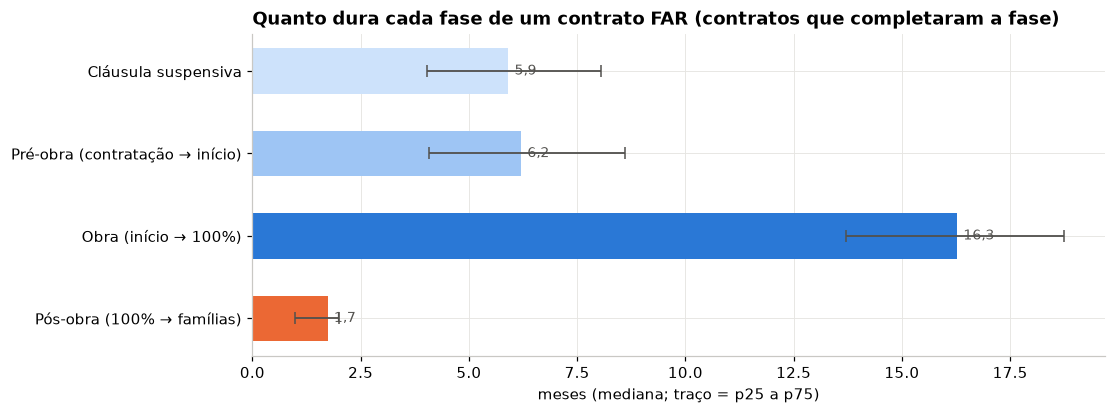

Obras ainda em execução: 739 (há 14.5 meses, mediana). Obras a 100% esperando famílias: 13 (há 1.0 meses, mediana).


In [3]:
m["d_susp"] = meses(m.dt_contratacao, m.fim_suspensiva)
m["d_pre"] = meses(m.dt_contratacao, m.inicio_obra)
m["d_obra"] = meses(m.inicio_obra, m.fim_obra)
m["d_pos"] = meses(m.fim_obra, m.entrada_familias)
m["d_total"] = meses(m.dt_contratacao, m.entrada_familias)
# fases em andamento (censuradas em HOJE)
m["d_obra_aberta"] = np.where(m.inicio_obra.notna() & m.fim_obra.isna() & ~m.distratado, meses(m.inicio_obra, pd.Series(HOJE, index=m.index)), np.nan)
m["d_pos_aberta"] = np.where(m.fim_obra.notna() & m.entrada_familias.isna() & ~m.distratado, meses(m.fim_obra, pd.Series(HOJE, index=m.index)), np.nan)
fases = pd.DataFrame({
    "Cláusula suspensiva": m.d_susp, "Pré-obra (contratação → início)": m.d_pre, "Obra (início → 100%)": m.d_obra,
    "Pós-obra (100% → famílias)": m.d_pos, "Total (contratação → famílias)": m.d_total})
res = fases.describe(percentiles=[.25, .5, .75]).T[["count","25%","50%","75%"]].rename(columns={"count": "contratos", "25%": "p25", "50%": "mediana", "75%": "p75"})
res["em andamento (não concluída)"] = [np.nan, np.nan, m.d_obra_aberta.notna().sum(), m.d_pos_aberta.notna().sum(), np.nan]
display(res.round(1))
fig, ax = plt.subplots(figsize=(10, 3.8))
r = res.iloc[:4][::-1]
ax.barh(r.index, r.mediana, color=[FASE_C["Cláusula suspensiva"], FASE_C["Pré-obra (aguardando início)"], FASE_C["Obra"], FASE_C["Pós-obra (100% sem entrega)"]][::-1], height=0.55)
ax.errorbar(r.mediana, range(len(r)), xerr=[r.mediana - r.p25, r.p75 - r.mediana], fmt="none", ecolor="#52514e", capsize=4, lw=1.2)
ax.set_xlabel("meses (mediana; traço = p25 a p75)"); ax.set_title("Quanto dura cada fase de um contrato FAR (contratos que completaram a fase)")
rotular_barras(ax, fmt=lambda v: f"{v:.1f}".replace(".", ","), horizontal=True)
plt.show()
print(f"Obras ainda em execução: {m.d_obra_aberta.notna().sum()} (há {m.d_obra_aberta.median():.1f} meses, mediana). Obras a 100% esperando famílias: {m.d_pos_aberta.notna().sum()} (há {m.d_pos_aberta.median():.1f} meses, mediana).")

**Leitura.** A pré-obra mediana é de meio ano, e a cláusula suspensiva ocupa quase tudo isso: o contrato é assinado, mas a obra só começa quando o ente cumpre a condição (lei autorizativa, orçamento das contrapartidas). A obra típica que já terminou levou pouco mais de um ano, mas a amostra de obras concluídas é pequena e enviesada para as rápidas. O pós-obra, para quem já teve famílias registradas, é curto (um a dois meses); o problema aparece nas obras a 100% que ainda não têm entrega nem contrato PF registrado, e nas que já têm famílias com contrato sem a CAIXA registrar a entrega (a linha "registro de entrega" da seção 5).

## 3. A carteira sobre a escala do contrato

Cada APF deslocado para o mês 0 da contratação. Em cima, a distribuição da carteira por fase em cada mês de contrato (que fração dos contratos está em suspensiva, aguardando início, em obra, concluída sem entrega, entregue ou distratada). Embaixo, no mesmo eixo, a curva S física da obra (média aparada da carteira, com a faixa p20 a p80). É a "curva média do contrato" que a pergunta pedia: a curva S, mais o que acontece antes e depois dela.

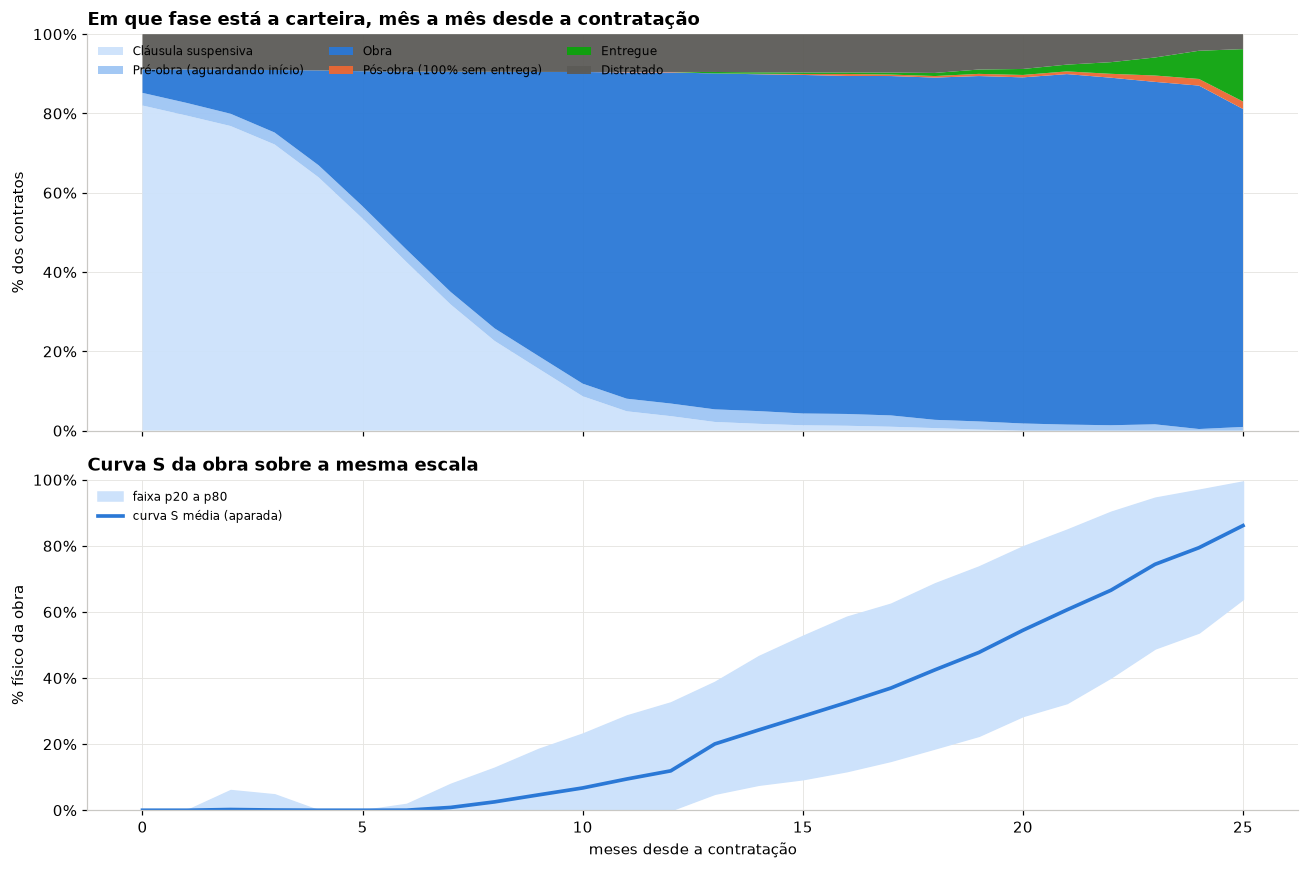

Fase dominante por mês de contrato (mediana da carteira):


fase,Cláusula suspensiva,Pré-obra (aguardando início),Obra,Pós-obra (100% sem entrega),Entregue,Distratado
mes_contrato,,,,,,
0,82,3,6,0,0,9
3,72,3,16,0,0,9
6,42,3,45,0,0,9
9,16,3,72,0,0,10
12,4,3,83,0,0,10
15,1,3,85,0,0,10
18,1,2,86,0,1,10
21,0,2,88,1,2,8
24,0,0,87,2,7,4


In [4]:
serie = cache("far_serie_mensal_apf", """
select apf, uf, mes, dt_inicio_obra, mes_inicio_fisico, etapa, pct_obra_realizada, pct_obra_prevista, desvio_fisico, fonte_fisica, situacao_obra,
       vr_liberado_mes, vr_liberado_acum, vr_emprestimo_far, pct_financeiro, situacao_caixa, pct_execucao_caixa, ritmo_fisico_financeiro
from ouro.ouro_far_serie_mensal_apf""")
serie["mes"] = pd.to_datetime(serie.mes)
sm = serie.merge(m[["apf","dt_contratacao","inicio_obra","fim_obra","entrada_familias","distratado","quantidade_uh"]], on="apf", how="left")
sm = sm[sm.dt_contratacao.notna()].copy(); sm["distratado"] = sm.distratado.fillna(False).astype(bool)
sm["mes_contrato"] = ((sm.mes.dt.year - sm.dt_contratacao.dt.year)*12 + (sm.mes.dt.month - sm.dt_contratacao.dt.month))
def fase_no_mes(r):
    if r.distratado: return "Distratado"
    if pd.notna(r.entrada_familias) and r.mes >= r.entrada_familias.to_period("M").to_timestamp(): return "Entregue"
    if pd.notna(r.fim_obra) and r.mes >= r.fim_obra: return "Pós-obra (100% sem entrega)"
    if pd.notna(r.inicio_obra) and r.mes >= r.inicio_obra.to_period("M").to_timestamp(): return "Obra"
    if r.etapa == "Cláusula suspensiva": return "Cláusula suspensiva"
    return "Pré-obra (aguardando início)"
sm["fase"] = sm.apply(fase_no_mes, axis=1)
ORDEM_F = ["Cláusula suspensiva", "Pré-obra (aguardando início)", "Obra", "Pós-obra (100% sem entrega)", "Entregue", "Distratado"]
dist = sm[sm.mes_contrato >= 0].pivot_table(index="mes_contrato", columns="fase", values="apf", aggfunc="nunique").fillna(0).reindex(columns=ORDEM_F, fill_value=0)
dist = dist[dist.sum(axis=1) >= 30]
share = dist.div(dist.sum(axis=1), axis=0) * 100

ativos = sm[~sm.distratado & sm.pct_obra_realizada.notna() & (sm.fonte_fisica != "carregado") & (sm.mes_contrato >= 0)]
g = ativos.groupby("mes_contrato").pct_obra_realizada
regua = pd.DataFrame({"n": g.size(), "p20": g.quantile(.2), "p80": g.quantile(.8), "ap": g.apply(lambda s: s[(s >= s.quantile(.2)) & (s <= s.quantile(.8))].mean())})
regua = regua[regua.n >= 15]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
axes[0].stackplot(share.index, [share[c] for c in ORDEM_F], labels=ORDEM_F, colors=[FASE_C[c] for c in ORDEM_F], alpha=0.95)
axes[0].set_ylim(0, 100); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[0].set_ylabel("% dos contratos")
axes[0].set_title("Em que fase está a carteira, mês a mês desde a contratação"); axes[0].legend(loc="upper left", fontsize=8, ncol=3)
axes[1].fill_between(regua.index, regua.p20, regua.p80, color="#cde2fb", label="faixa p20 a p80")
axes[1].plot(regua.index, regua.ap, color=C["azul"], lw=2.4, label="curva S média (aparada)")
axes[1].set_ylim(0, 100); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[1].set_ylabel("% físico da obra"); axes[1].set_xlabel("meses desde a contratação")
axes[1].set_title("Curva S da obra sobre a mesma escala"); axes[1].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()
print("Fase dominante por mês de contrato (mediana da carteira):")
display(share.round(0).astype(int).loc[[0, 3, 6, 9, 12, 15, 18, 21, 24]] if 24 in share.index else share.round(0).astype(int))

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: a fase de cada APF em cada mês é uma regra deste notebook</b><ul style="margin:6px 0 0 0"><li>A função <code>fase_no_mes</code> decide a fase pela ordem: distratado, entregue (entrega da CAIXA ou primeiro contrato PF), pós-obra (100% atingido), obra (a partir do início do cadastro PJ, com a primeira liberação como reserva), cláusula suspensiva (etapa da série) e, no resto, pré-obra. A escolha do início do cadastro no lugar do "início físico observado" é deste notebook, por causa da medição da CAIXA só existir desde abril de 2025 (fato documentado no modelo da série, issue #163, e confirmado nos dados).</li><li><b>Como levar ao banco:</b> coluna <code>fase_contrato</code> na <code>ouro.ouro_far_serie_mensal_apf</code> com essa regra, e uma tabela <code>ouro.ouro_far_marcos_apf</code> (um APF por linha com todos os marcos), que hoje é o parquet <code>data/interim/far_marcos_apf.parquet</code> montado por este notebook.</li></ul></div>

**Leitura.** Nos primeiros seis meses a carteira é quase toda cláusula suspensiva e preparação; a obra domina do 7º ao 20º mês; a partir daí começam a aparecer as concluídas sem entrega. A curva S só sai do zero por volta do 7º mês de contrato porque é aí que a obra começa de fato. Qualquer meta de "entrega em N meses" precisa ser contada a partir da contratação com esses seis meses de pré-obra dentro.

## 4. Cada contrato no calendário

Uma linha por APF, ordenada pela data de contratação. A barra mostra as fases no tempo real: dá para ver os ciclos de contratação (2024 e 2025/26), quanto tempo cada bloco ficou em pré-obra e quais já chegaram ao fim.

Contratos com início de obra anterior à contratação no cadastro PJ (data suspeita, mostrados a partir da contratação): 4


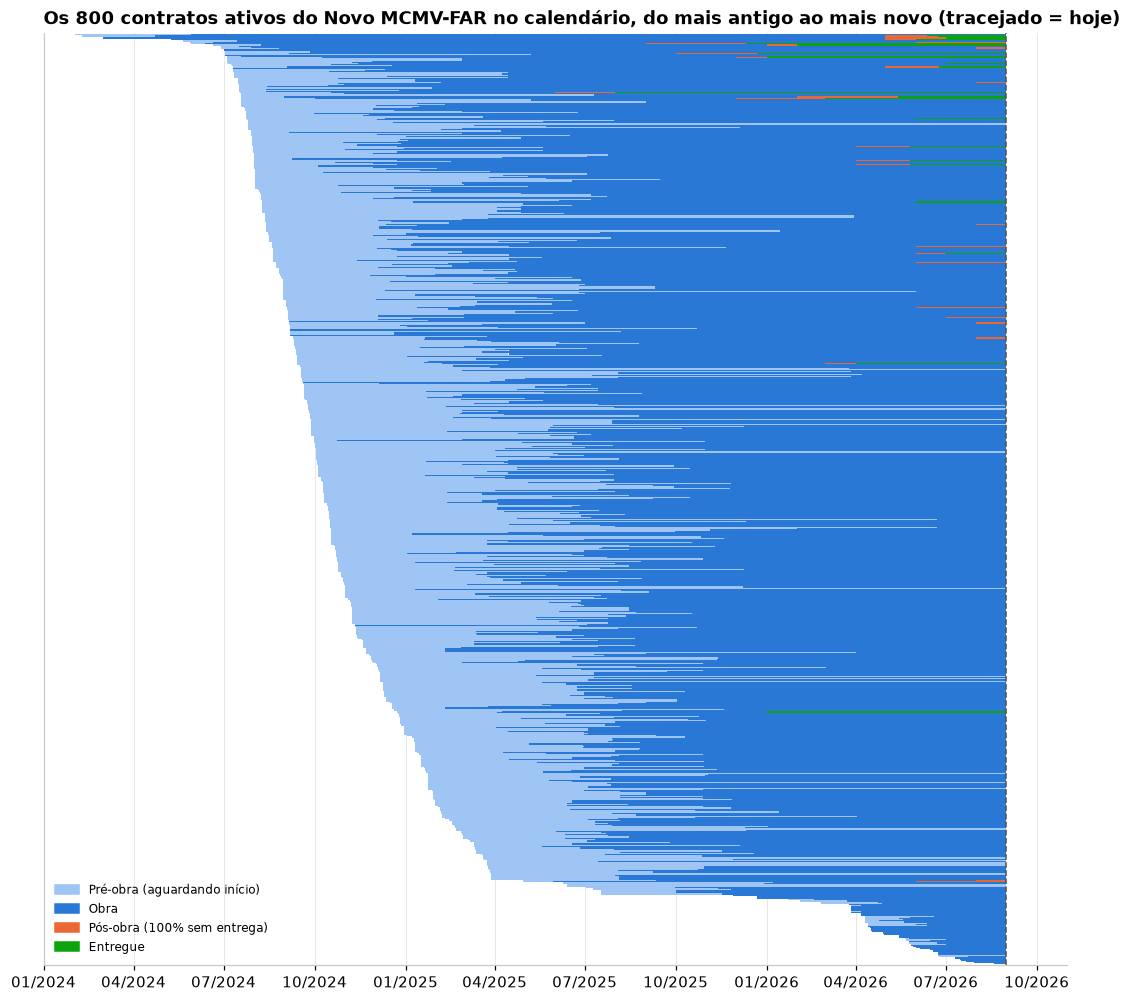

In [5]:
g = m[~m.distratado].sort_values("dt_contratacao").reset_index(drop=True)
anom = (g.inicio_obra < g.dt_contratacao).sum()
print(f"Contratos com início de obra anterior à contratação no cadastro PJ (data suspeita, mostrados a partir da contratação): {anom}")
g["inicio_obra"] = g[["inicio_obra", "dt_contratacao"]].max(axis=1).where(g.inicio_obra.notna())
fig, ax = plt.subplots(figsize=(12, 11))
for i, r in g.iterrows():
    t0 = r.dt_contratacao; t1 = r.inicio_obra if pd.notna(r.inicio_obra) else HOJE
    ax.barh(i, (t1 - t0).days, left=t0, color=FASE_C["Pré-obra (aguardando início)"], height=1, linewidth=0)
    if pd.notna(r.inicio_obra):
        t2 = r.fim_obra if pd.notna(r.fim_obra) else HOJE
        ax.barh(i, (t2 - r.inicio_obra).days, left=r.inicio_obra, color=FASE_C["Obra"], height=1, linewidth=0)
    if pd.notna(r.fim_obra):
        t3 = r.entrada_familias if pd.notna(r.entrada_familias) else HOJE
        ax.barh(i, (t3 - r.fim_obra).days, left=r.fim_obra, color=FASE_C["Pós-obra (100% sem entrega)"], height=1, linewidth=0)
    if pd.notna(r.entrada_familias):
        ax.barh(i, (HOJE - r.entrada_familias).days, left=r.entrada_familias, color=FASE_C["Entregue"], height=1, linewidth=0)
ax.set_ylim(-1, len(g)); ax.invert_yaxis(); ax.set_yticks([]); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.axvline(HOJE, color="#52514e", lw=1, ls="--"); ax.set_xlim(pd.Timestamp("2024-01-01"), pd.Timestamp("2026-10-31"))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=FASE_C[k], label=k) for k in ["Pré-obra (aguardando início)", "Obra", "Pós-obra (100% sem entrega)", "Entregue"]], loc="lower left", fontsize=8)
ax.set_title(f"Os {len(g)} contratos ativos do Novo MCMV-FAR no calendário, do mais antigo ao mais novo (tracejado = hoje)")
plt.show()

## 5. Em que fase o atraso acontece

A base não tem um campo "motivo do atraso": os campos do MONIT feitos para isso vêm vazios e o GEHIS traz o status sem justificativa. O que dá para medir é **onde** o contrato está parado além do normal, usando a própria carteira como régua (acima do p80 da fase) e as regras que existem:

- **Pré-obra**: contratação há mais de 9 meses (p80 da carteira) sem início de obra; a cláusula suspensiva deveria ser resolvida em até 90 dias (MNPO).
- **Obra**: abaixo da faixa p20 da curva S no último mês observado, ou promessa original de conclusão vencida sem chegar a 100%.
- **Pós-obra**: 100% há três meses ou mais sem entrega nem contrato de família registrado.
- **Registro de entrega**: famílias com contrato assinado e a CAIXA ainda sem `uh_entregues` nos Dados Prioritários (atraso de registro, não de obra).

Para cada contrato atrasado, o que a base diz: o status GEHIS (em atenção, risco, paralisado), a situação da CAIXA com o detalhamento (só existe para paralisadas) e, no pós-obra, se as famílias já assinaram (o atraso é de registro) ou não (o atraso é de habite-se, legalização ou designação).

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: as réguas de atraso por fase e a data de hoje</b><ul style="margin:6px 0 0 0"><li>"Pré-obra atrasada" = sem início após o p80 da própria carteira (cerca de 9 meses); "obra atrasada" = abaixo do p20 da curva S ou promessa original vencida; "pós-obra atrasada" = 100% há 3 meses ou mais sem famílias; "registro pendente" = famílias com contrato e CAIXA sem UH entregue. Todas são regras deste notebook, com a data de hoje fixada em 31/08/2026.</li><li>O motivo do atraso não existe na base em nenhuma fase.</li><li><b>Como levar ao banco:</b> modelo <code>ouro.ouro_far_atraso_por_fase</code> com as réguas como parâmetros (vars do dbt) e a data de posição vinda da própria carga; o motivo entra pela ficha do empreendimento com gestão do trabalho (ações, datas, atores), como pediu o secretário.</li></ul></div>

,contratos na fase,atrasados,UH atrasadas,% da fase atrasada
Pré-obra,25,24,3965,96.0
Obra,739,201,29685,27.0
Pós-obra,13,0,0,0.0
Registro de entrega,22,7,1100,32.0


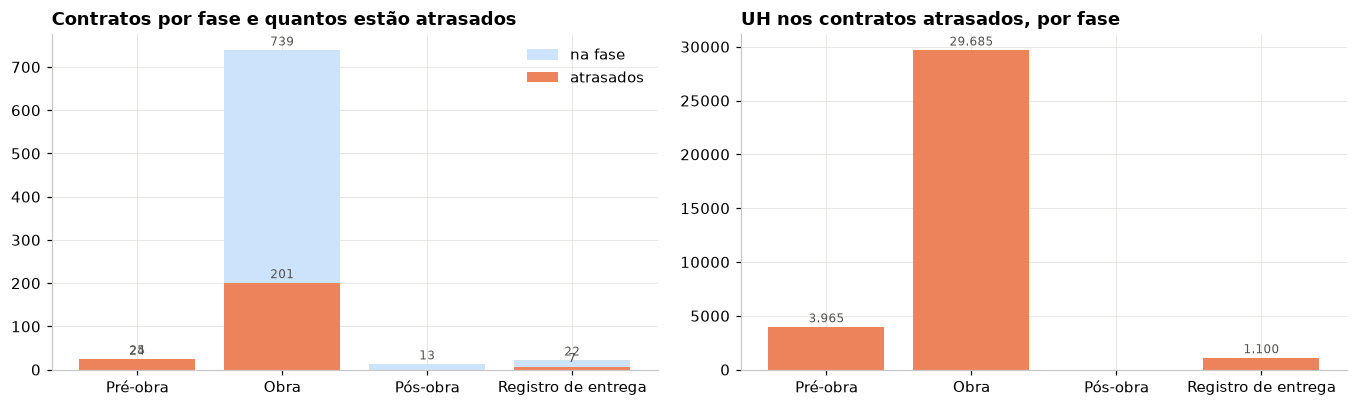

In [6]:
gehis = cache("far_gehis_mensal", """
with g as (
  select nu_apf as apf, coalesce(nullif(nu_anomes,''), anomes) as anomes, upper(trim(situacao_obra)) as situacao, _source_file
  from bronze.bronze_sftp_gehis_andamento_obra
  where nu_apf ~ '^[0-9]{8}$' and coalesce(nullif(nu_anomes,''), anomes) ~ '^20[0-9]{4}$'
), ult as (select anomes, max(_source_file) as arq from g group by anomes)
select g.apf, g.anomes, g.situacao from g join ult on ult.anomes = g.anomes and ult.arq = g._source_file
where g.apf in (select apf from ouro.ouro_far_ficha_empreendimento)""")
gehis["situacao"] = gehis.situacao.str.replace("Ç","C").str.replace("Ã","A").str.replace("INAOMPLETO","INCOMPLETO").replace({"": "SEM INFORMACAO"})
g_ult = gehis.sort_values("anomes").groupby("apf").tail(1).set_index("apf").situacao.rename("gehis")
cxd = cache("far_caixa_detalhe", "select apf, situacao, situacao_detalhamento from prata.prata_far_caixa_serie where competencia = (select max(competencia) from prata.prata_far_caixa_serie)").set_index("apf")
ult_serie = ativos.sort_values("mes").groupby("apf").tail(1).set_index("apf")[["mes_contrato","pct_obra_realizada"]].join(regua[["p20"]], on="mes_contrato")

a = m[~m.distratado].copy().set_index("apf")
a["gehis"] = g_ult; a["caixa_detalhe"] = cxd.situacao_detalhamento
a["pre_meses"] = np.where(a.inicio_obra.isna(), meses(a.dt_contratacao, pd.Series(HOJE, index=a.index)), np.nan)
P80_PRE = m.d_pre.quantile(.8)
a["atraso_pre"] = a.inicio_obra.isna() & (a.pre_meses > P80_PRE)
a["abaixo_p20"] = a.index.map(lambda k: ult_serie.pct_obra_realizada.get(k, np.nan) < ult_serie.p20.get(k, np.nan))
a["atraso_obra"] = a.inicio_obra.notna() & a.fim_obra.isna() & (a.abaixo_p20 | (a.dt_previsao_conclusao < HOJE))
a["atraso_pos"] = a.fim_obra.notna() & a.entrada_familias.isna() & (a.d_pos_aberta >= 3)
a["pos_familias_assinaram"] = a.atraso_pos & a.pf0.notna()
a["registro_pendente"] = a.pf0.notna() & a.m_entrega0.isna()   # famílias assinaram, CAIXA ainda sem uh_entregues
resumo = pd.DataFrame({
    "contratos na fase": [a.inicio_obra.isna().sum(), (a.inicio_obra.notna() & a.fim_obra.isna()).sum(), (a.fim_obra.notna() & a.entrada_familias.isna()).sum(), a.pf0.notna().sum()],
    "atrasados": [a.atraso_pre.sum(), a.atraso_obra.sum(), a.atraso_pos.sum(), a.registro_pendente.sum()],
    "UH atrasadas": [a.loc[a.atraso_pre, "quantidade_uh"].sum(), a.loc[a.atraso_obra, "quantidade_uh"].sum(), a.loc[a.atraso_pos, "quantidade_uh"].sum(), a.loc[a.registro_pendente, "quantidade_uh"].sum()],
}, index=["Pré-obra", "Obra", "Pós-obra", "Registro de entrega"])
resumo["% da fase atrasada"] = (100 * resumo.atrasados / resumo["contratos na fase"]).round(0)
display(resumo)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].bar(resumo.index, resumo["contratos na fase"], color="#cde2fb", label="na fase"); axes[0].bar(resumo.index, resumo.atrasados, color=STATUS["serio"], label="atrasados")
axes[0].set_title("Contratos por fase e quantos estão atrasados"); axes[0].legend(); rotular_barras(axes[0], fontsize=8)
axes[1].bar(resumo.index, resumo["UH atrasadas"], color=STATUS["serio"]); axes[1].set_title("UH nos contratos atrasados, por fase"); rotular_barras(axes[1], fontsize=8)
plt.tight_layout(); plt.show()

PRÉ-OBRA atrasada: status GEHIS e detalhamento CAIXA


,,contratos,uh
gehis,caixa_detalhe,,
OBRA NAO INICIADA,NÃO SE APLICA,24,3965


OBRA atrasada: status GEHIS e detalhamento CAIXA


,,contratos,uh
gehis,caixa_detalhe,,
EM ATENCAO,NÃO SE APLICA,126,19592
NORMAL,NÃO SE APLICA,56,7336
OBRA NAO INICIADA,NÃO SE APLICA,5,668
RISCO DE PARALISACAO,NÃO SE APLICA,4,692
TRATAMENTO CUSTOMIZADO,A RETOMAR - SOLUÇÃO LOCAL,3,528
OBRA RETOMADA,NÃO SE APLICA,2,77
PARALISADO,A RETOMAR - APORTE SUPLEMENTAR,2,300
CRONOGRAMA INCOMPLETO,NÃO SE APLICA,1,150
PARALISADO,NÃO SE APLICA,1,192


PÓS-OBRA atrasada: o que falta


,,contratos,uh
pos_tipo,gehis,,


REGISTRO DE ENTREGA pendente: famílias com contrato assinado e CAIXA sem UH entregue


,nome_empreendimento,municipio_uf,quantidade_uh,fim_obra,pf0,n_pf,gehis
apf,,,,,,,
62663083,RESIDENCIAL VILA FLORIDA V,Matão/SP,90,2025-09-01,2025-12-11,90.0,OBRA SOLUCIONADA
63135226,RESIDENCIAL JARDIM PORTO FRANCO I,Porto Franco/MA,50,2025-10-01,2025-12-22,50.0,SEM INFORMACAO
62743758,VERDES HORIZONTES I,Camaçari/BA,192,2026-02-01,2026-05-14,171.0,SEM INFORMACAO
62743976,VERDES HORIZONTES II,Camaçari/BA,192,2026-02-01,2026-05-14,190.0,SEM INFORMACAO
63433677,MORAR MELHOR 13,Manaus/AM,192,2026-04-01,2026-05-26,191.0,SEM INFORMACAO
63433781,MORAR MELHOR 14,Manaus/AM,192,2026-04-01,2026-05-26,154.0,SEM INFORMACAO
63433908,MORAR MELHOR 15,Manaus/AM,192,2026-04-01,2026-05-26,178.0,SEM INFORMACAO


Lista completa em output/far_contratos_atrasados_por_fase.csv


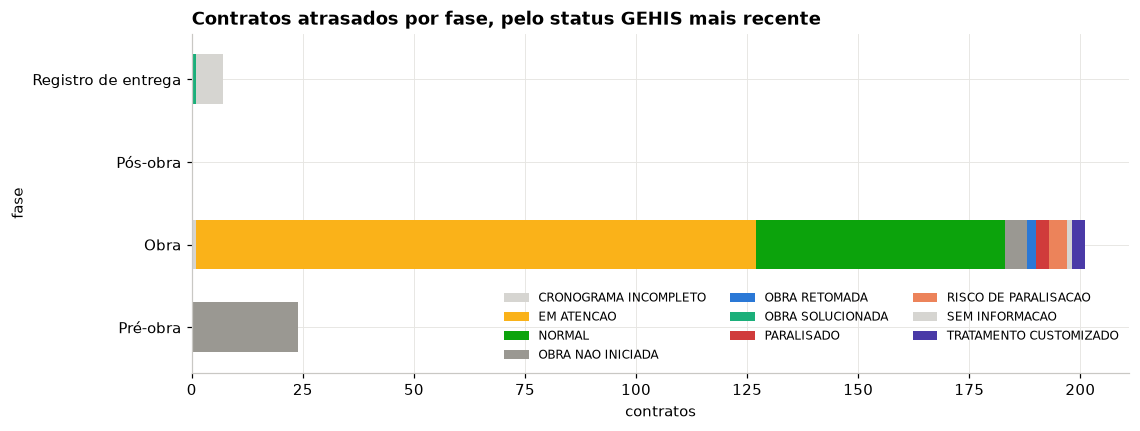

In [7]:
# O que a base diz sobre cada atraso, por fase
def tabela(mask, cols):
    t = a[mask].groupby(cols, dropna=False).agg(contratos=("quantidade_uh","size"), uh=("quantidade_uh","sum")).sort_values("contratos", ascending=False)
    return t
print("PRÉ-OBRA atrasada: status GEHIS e detalhamento CAIXA"); display(tabela(a.atraso_pre, ["gehis","caixa_detalhe"]).head(8))
print("OBRA atrasada: status GEHIS e detalhamento CAIXA"); display(tabela(a.atraso_obra, ["gehis","caixa_detalhe"]).head(10))
a["pos_tipo"] = np.select([a.atraso_pos & a.pf0.notna(), a.atraso_pos & a.pf0.isna()], ["famílias já assinaram: entrega não registrada pela CAIXA", "sem contrato de família: habite-se, legalização ou designação pendente"], "")
print("PÓS-OBRA atrasada: o que falta"); display(tabela(a.atraso_pos, ["pos_tipo","gehis"]))
print("REGISTRO DE ENTREGA pendente: famílias com contrato assinado e CAIXA sem UH entregue"); display(a[a.registro_pendente][["nome_empreendimento","municipio_uf","quantidade_uh","fim_obra","pf0","n_pf","gehis"]].sort_values("pf0"))
lista = a[a.atraso_pre | a.atraso_obra | a.atraso_pos | a.registro_pendente].copy()
lista["fase_atrasada"] = np.select([lista.atraso_pre, lista.atraso_obra, lista.atraso_pos, lista.registro_pendente], ["Pré-obra", "Obra", "Pós-obra", "Registro de entrega"], default="")
lista.reset_index()[["apf","nome_empreendimento","municipio_uf","quantidade_uh","fase_atrasada","dt_contratacao","inicio_obra","fim_obra","dt_previsao_conclusao","percentual_execucao_fisica","gehis","caixa_detalhe","pos_tipo","pf0","n_pf"]].sort_values(["fase_atrasada","dt_contratacao"]).to_csv(OUT / "far_contratos_atrasados_por_fase.csv", index=False)
print("Lista completa em output/far_contratos_atrasados_por_fase.csv")
fig, ax = plt.subplots(figsize=(11, 4))
tg = a[a.atraso_pre | a.atraso_obra | a.atraso_pos | a.registro_pendente].assign(fase=lambda d: np.select([d.atraso_pre, d.atraso_obra, d.atraso_pos, d.registro_pendente], ["Pré-obra", "Obra", "Pós-obra", "Registro de entrega"], default=""))
ct = pd.crosstab(tg.fase, tg.gehis.fillna("fora do GEHIS")).reindex(["Pré-obra", "Obra", "Pós-obra", "Registro de entrega"]).fillna(0)
ct.plot.barh(stacked=True, ax=ax, color=[{"NORMAL": STATUS["bom"], "EM ATENCAO": STATUS["atencao"], "RISCO DE PARALISACAO": STATUS["serio"], "PARALISADO": STATUS["critico"], "OBRA NAO INICIADA": C["cinza"], "OBRA SOLUCIONADA": C["verde"], "OBRA RETOMADA": C["azul"], "TRATAMENTO CUSTOMIZADO": C["roxo"]}.get(c, "#d6d5d1") for c in ct.columns], width=0.6)
ax.set_title("Contratos atrasados por fase, pelo status GEHIS mais recente"); ax.set_xlabel("contratos"); ax.legend(fontsize=8, ncol=3, loc="lower right")
plt.show()

**Leitura.** O atraso está concentrado na obra, e não por paralisação: a maior parte dos contratos atrasados está "em atenção" no GEHIS, ou seja, anda abaixo do ritmo sem ter parado. No pré-obra, a carteira ainda tem contratos de 2024 e 2025 sem obra iniciada depois de nove meses, e o GEHIS os marca como "obra não iniciada", sem dizer por quê (a cláusula suspensiva do ente é a hipótese mais provável). No pós-obra o diagnóstico é o mais preciso de todos: dá para separar as obras a 100% sem famílias (falta habite-se, legalização ou designação) das que já têm contrato de família assinado e a CAIXA ainda não registrou a entrega nos Dados Prioritários (a linha "registro de entrega": a entrega aconteceu, o registro é que não chegou). Os motivos em si continuam fora da base.

## 6. O caso do Residencial Vila Florida V (Matão/SP)

90 unidades, contratado em 29/05/2024. A ficha diz "em andamento, 100% executado, sem entrega". Juntando todos os marcos:

,data,meses desde a contratação
marco,,
Contratação,2024-05-29,0.0
"Cláusula suspensiva (série, mês da contratação)",2024-05-29,0.0
Início da obra (cadastro PJ),2024-06-12,0.5
Primeira liberação do FAR,2024-08-01,2.1
CAIXA passa a medir (80% já executado),2025-04-01,10.1
100% de execução,2025-09-01,15.1
Promessa original de conclusão,2025-12-12,18.5
MONIT: obra concluída,2025-12-01,18.1
90 contratos de famílias assinados,2025-12-11,18.4


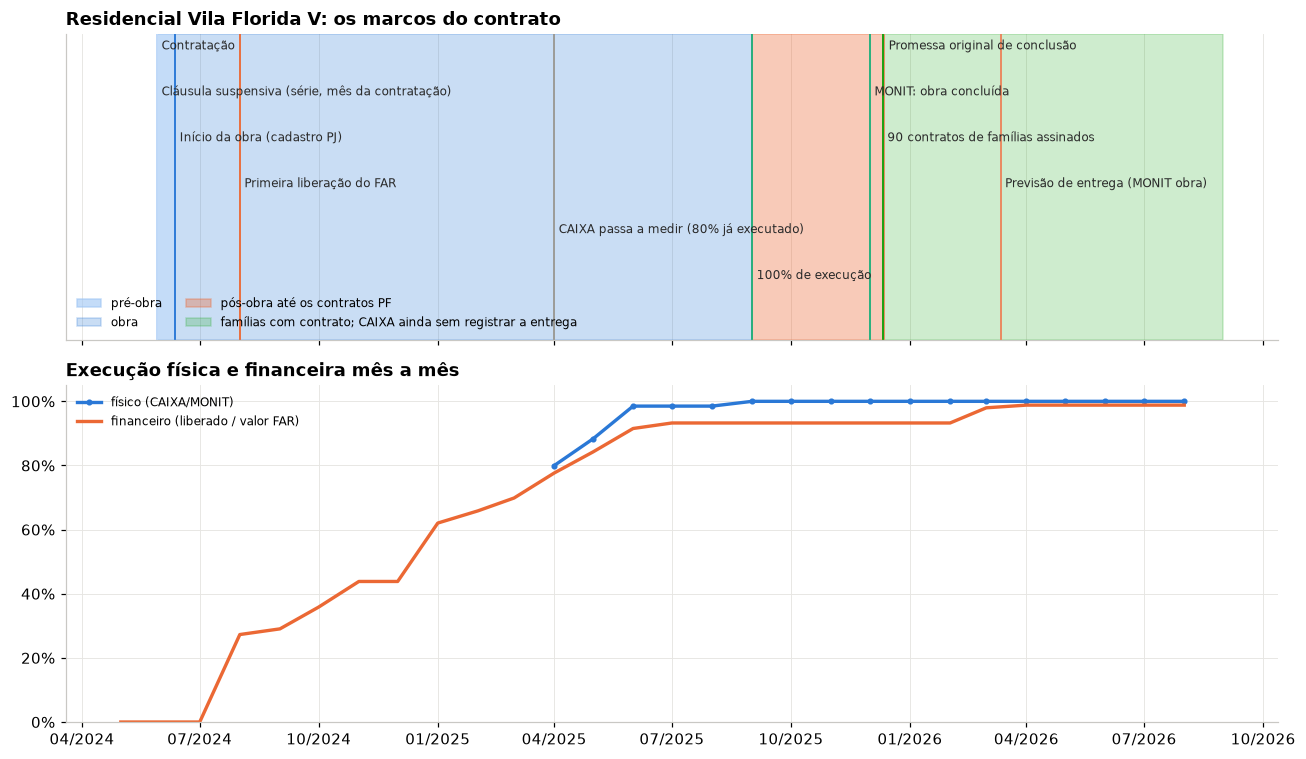

Status GEHIS ao longo do tempo:


,min,max,count
situacao,,,
EM ANDAMENTO,202504,202504,1
NORMAL,202407,202511,14
OBRA NAO INICIADA,202406,202406,1
OBRA SOLUCIONADA,202512,202608,8
SEM INFORMACAO,202408,202506,2


In [8]:
apf = m.loc[m.nome_empreendimento.str.contains("VILA FLORIDA V", na=False), "apf"].iloc[0]
r = m.set_index("apf").loc[apf]
sv = serie[serie.apf == apf].sort_values("mes")
gv = gehis[gehis.apf == apf].sort_values("anomes")
marcos = [
    ("Contratação", r.dt_contratacao, C["azul"]),
    ("Cláusula suspensiva (série, mês da contratação)", max(r.m_susp0, r.dt_contratacao), FASE_C["Cláusula suspensiva"]),
    ("Início da obra (cadastro PJ)", r.dt_inicio_obra, C["azul"]),
    ("Primeira liberação do FAR", r.m_lib0, C["laranja"]),
    ("CAIXA passa a medir (80% já executado)", r.m_exec0, C["cinza"]),
    ("100% de execução", r.m_100, C["verde"]),
    ("Promessa original de conclusão", r.dt_previsao_conclusao, STATUS["serio"]),
    ("MONIT: obra concluída", r.m_concl_monit, C["verde"]),
    ("90 contratos de famílias assinados", r.pf0, STATUS["bom"]),
    ("Previsão de entrega (MONIT obra)", r.prev_ent_monit, STATUS["serio"]),
    ("Entrega registrada pela CAIXA", r.m_entrega0, STATUS["critico"]),
]
tab = pd.DataFrame([(n, d) for n, d, _ in marcos], columns=["marco", "data"]).set_index("marco")
tab["meses desde a contratação"] = ((tab.data - r.dt_contratacao).dt.days / 30.44).round(1)
display(tab)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.1]})
ax = axes[0]
ax.axvspan(r.dt_contratacao, r.dt_inicio_obra, color=FASE_C["Pré-obra (aguardando início)"], alpha=0.6, label="pré-obra")
ax.axvspan(r.dt_inicio_obra, r.m_100, color=FASE_C["Obra"], alpha=0.25, label="obra")
ax.axvspan(r.m_100, r.pf0, color=FASE_C["Pós-obra (100% sem entrega)"], alpha=0.35, label="pós-obra até os contratos PF")
ax.axvspan(r.pf0, HOJE, color=FASE_C["Entregue"], alpha=0.2, label="famílias com contrato; CAIXA ainda sem registrar a entrega")
for k, (n, d, cor) in enumerate(marcos):
    if pd.isna(d): continue
    ax.axvline(d, color=cor, lw=1.2); ax.annotate(n, (d, 0.95 - (k % 6) * 0.15), xycoords=("data", "axes fraction"), fontsize=8, rotation=0, color="#2a2a2a", xytext=(3, 0), textcoords="offset points")
ax.set_yticks([]); ax.set_title("Residencial Vila Florida V: os marcos do contrato"); ax.legend(loc="lower left", fontsize=8, ncol=2)
ax = axes[1]
ax.plot(sv.mes, sv.pct_obra_realizada, color=C["azul"], lw=2.2, marker="o", ms=3, label="físico (CAIXA/MONIT)")
ax.plot(sv.mes, sv.pct_financeiro, color=C["laranja"], lw=2.2, label="financeiro (liberado / valor FAR)")
ax.set_ylim(0, 105); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Execução física e financeira mês a mês"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
plt.tight_layout(); plt.show()
print("Status GEHIS ao longo do tempo:"); display(gv.groupby("situacao").anomes.agg(["min","max","count"]))

**O que aconteceu com o Vila Florida V.** A cronologia que os dados contam:

1. Contratado em 29/05/2024 e, pelo cadastro PJ, a obra começou em 12/06/2024, duas semanas depois. A série marca maio de 2024 como cláusula suspensiva e junho em diante como "aguardando início físico", mas o dinheiro começa a sair em agosto de 2024 (R$ 3,5 mi) e o financeiro chega a 70% em março de 2025: a obra estava andando, só não estava sendo medida, porque a CAIXA só passou a informar o físico do Novo MCMV em abril de 2025, quando este empreendimento já estava em 80%. A fase "pré-obra" longa que a série sugere é um artefato da medição, não um atraso real.
2. A obra chegou a 100% em setembro de 2025, 16 meses depois da contratação e três meses antes da promessa original (12/12/2025). O GEHIS a manteve "normal" o tempo todo e a marcou "obra solucionada" a partir de dezembro de 2025, quando o MONIT registrou "concluída".
3. Em 11/12/2025 os 90 contratos das famílias foram assinados no mesmo dia: a entrada das famílias aconteceu. O financeiro ainda recebeu as últimas liberações em março e abril de 2026 (retenções finais, legalização), chegando a 98,8%.
4. Desde então, nada muda no retrato mensal da CAIXA: situação "em andamento", 0 UH entregues, até julho de 2026. A previsão de entrega do MONIT (12/03/2026) também passou. O "grande atraso no final" que aparece na ficha é, na maior parte, atraso de registro: o empreendimento foi entregue às famílias em dezembro de 2025 e a base dos Dados Prioritários não refletiu isso oito meses depois.

A lição para o painel: a entrega precisa ser lida por três fontes em conjunto (100% físico, contrato das famílias e `uh_entregues` da CAIXA), e a divergência entre elas é em si um indicador: quando as famílias assinaram e a CAIXA não registrou, é pendência de registro, não de obra. Para saber se há algo real pendente nesse caso (habite-se, ligações, legalização), só perguntando à GIHAB de Matão ou olhando os ofícios.

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: a leitura do caso é interpretação sobre dados do banco</b><ul style="margin:6px 0 0 0"><li>As datas e valores são todos do banco. A conclusão de que o atraso final é de registro (famílias assinaram em 11/12/2025 e a CAIXA não registrou a entrega) é inferência: o banco não diz por que os Dados Prioritários não foram atualizados nem se há pendência real (habite-se, ligações, legalização).</li><li><b>Como fechar:</b> confirmar com a GIHAB de Matão ou com o DPH; e, no banco, o indicador "registro de entrega pendente" (contrato PF sem <code>uh_entregues</code>) como coluna da ficha, para que casos assim apareçam sozinhos.</li></ul></div>

## 7. Síntese

- O contrato FAR típico tem seis meses de pré-obra, dominados pela cláusula suspensiva, antes de a obra começar. A curva S sozinha esconde isso.
- A obra concluída típica levou pouco mais de um ano, mas a amostra ainda é pequena; a maior parte da carteira está entre o 12º e o 24º mês de contrato, em obra.
- O atraso, pela régua da própria carteira, está concentrado na obra e aparece no GEHIS como "em atenção". No pós-obra, metade dos casos é atraso de registro (famílias já assinaram), não de entrega.
- A base não traz motivo de atraso em nenhuma fase: os campos do MONIT estão vazios e o GEHIS não justifica. Preencher isso é a "gestão do trabalho" da ficha do empreendimento.
- Próximo passo: ligar a fase 1 ao consolidado do GFAR (datas de protocolo, enquadramento e aptidão), para a linha do tempo começar antes do contrato, e usar o histórico pré-2024 para medir a fase 3 com obras entregues de verdade.